# Brasil em Dados

## Aprendizado de máquina supervisionado

Este notebook compara métodos de classificação para investigar se
informações socioeconômicas municipais ajudam a distinguir municípios
com IDEB acima da mediana do conjunto de treino daqueles com IDEB igual
ou abaixo dela.

Serão comparados um modelo de referência, KNN, árvore de decisão e
métodos ensemble. Como preditoras serão usados o logaritmo da população
municipal e o rendimento domiciliar per capita.

A classificação do IDEB é um recorte exploratório e didático. A mediana
não representa uma classificação oficial de qualidade educacional.

## 1. Carregamento e seleção das variáveis

Será carregada a base integrada do primeiro notebook. Serão usados
somente municípios com dados disponíveis para as variáveis selecionadas.

As notas e a taxa de aprovação não serão usadas como preditoras, pois são
indicadores educacionais relacionados à construção do IDEB. O objetivo
aqui é avaliar a informação contida nas variáveis socioeconômicas.

In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

PROJECT_ROOT = Path("..")
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

arquivo_base = DATA_PROCESSED / "brasil_em_dados_municipios.csv"

df_integrado = pd.read_csv(
    arquivo_base,
    encoding="utf-8-sig",
    dtype={"codigo_municipio": "Int64"}
)

print("Dimensões da base integrada:", df_integrado.shape)
display(df_integrado.head())

Dimensões da base integrada: (5569, 13)


,uf,codigo_municipio,municipio,REDE,taxa_aprovacao_2023,indicador_rendimento_2023,nota_matematica_2023,nota_portugues_2023,nota_media_2023,ideb_2023,populacao_2022,renda_domiciliar_per_capita_2022,observacao
0,RO,1100015,Alta Floresta D'Oeste,Pública,93.2,0.931733,254.11,246.21,5.005333,4.7,21494.0,1210.60,NaN
1,RO,1100023,Ariquemes,Pública,93.8,0.937832,251.95,251.99,5.065667,4.8,96833.0,1458.57,NaN
2,RO,1100031,Cabixi,Pública,99.7,0.997227,247.93,252.78,5.011833,5.0,5351.0,1323.79,NaN
3,RO,1100049,Cacoal,Pública,98.8,0.988228,247.61,249.67,4.954667,4.9,86887.0,1625.88,NaN
4,RO,1100056,Cerejeiras,Pública,96.7,0.966651,255.25,252.94,5.136500,5.0,15890.0,1554.33,NaN


## 2. Definição do problema de classificação

A variável-alvo original, o IDEB, é numérica. Para este exercício de
classificação, os municípios serão divididos em dois grupos:

- Classe 1: IDEB acima da mediana do conjunto de treino.
- Classe 0: IDEB igual ou abaixo dessa mediana.

A mediana será calculada depois da separação entre treino e teste. Assim,
o conjunto de teste não participa da definição do limiar usado para
construir as classes.

In [14]:
colunas_modelo = [
    "codigo_municipio",
    "municipio",
    "populacao_2022",
    "renda_domiciliar_per_capita_2022",
    "ideb_2023"
]

df_modelo = df_integrado[colunas_modelo].copy()

colunas_numericas = [
    "populacao_2022",
    "renda_domiciliar_per_capita_2022",
    "ideb_2023"
]

for coluna in colunas_numericas:
    df_modelo[coluna] = pd.to_numeric(
        df_modelo[coluna],
        errors="coerce"
    )

df_modelo = df_modelo.dropna(
    subset=[
        "populacao_2022",
        "renda_domiciliar_per_capita_2022",
        "ideb_2023"
    ]
).copy()

df_modelo["log_populacao_2022"] = np.log1p(
    df_modelo["populacao_2022"]
)

variaveis_preditora = [
    "log_populacao_2022",
    "renda_domiciliar_per_capita_2022"
]

X = df_modelo[variaveis_preditora]
y_continuo = df_modelo["ideb_2023"]

X_treino, X_teste, y_treino_continuo, y_teste_continuo = train_test_split(
    X,
    y_continuo,
    test_size=0.20,
    random_state=42
)

limiar_ideb = y_treino_continuo.median()

y_treino = (
    y_treino_continuo > limiar_ideb
).astype(int)

y_teste = (
    y_teste_continuo > limiar_ideb
).astype(int)

print("Municípios utilizados:", len(df_modelo))
print(f"Limiar calculado no treino: IDEB > {limiar_ideb:.2f}")
print("\nDistribuição das classes no treino:")
display(y_treino.value_counts().rename({
    0: "IDEB igual ou abaixo do limiar",
    1: "IDEB acima do limiar"
}).to_frame("quantidade"))

print("\nDistribuição das classes no teste:")
display(y_teste.value_counts().rename({
    0: "IDEB igual ou abaixo do limiar",
    1: "IDEB acima do limiar"
}).to_frame("quantidade"))

Municípios utilizados: 5382
Limiar calculado no treino: IDEB > 4.80

Distribuição das classes no treino:


,quantidade
ideb_2023,
IDEB igual ou abaixo do limiar,2242
IDEB acima do limiar,2063



Distribuição das classes no teste:


,quantidade
ideb_2023,
IDEB igual ou abaixo do limiar,574
IDEB acima do limiar,503


## 3. Modelo de referência e validação cruzada

O modelo de referência prevê sempre a classe mais frequente no conjunto
de treino. Os outros modelos devem ser comparados com esse resultado.

A validação cruzada será feita somente dentro do conjunto de treino. O
conjunto de teste ficará reservado para a avaliação final.

In [15]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

modelo_referencia = DummyClassifier(
    strategy="most_frequent"
)

modelo_referencia.fit(X_treino, y_treino)

print("Acurácia de referência no teste:",
      round(modelo_referencia.score(X_teste, y_teste), 3))

Acurácia de referência no teste: 0.533


## 4. Método baseado em distância — KNN

O KNN classifica um município considerando as classes dos municípios
mais próximos no espaço das variáveis preditoras.

Como a distância é sensível à escala das variáveis, a padronização será
incluída em um `Pipeline`. Dessa forma, em cada divisão da validação
cruzada, o padronizador será ajustado somente com os dados de treino
daquela divisão.

In [16]:
pipeline_knn = Pipeline([
    ("padronizador", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

grade_knn = {
    "knn__n_neighbors": [5, 9, 15, 21],
    "knn__weights": ["uniform", "distance"]
}

busca_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=grade_knn,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

busca_knn.fit(X_treino, y_treino)

print("Melhores parâmetros do KNN:", busca_knn.best_params_)
print(f"F1 médio na validação cruzada: {busca_knn.best_score_:.3f}")

Melhores parâmetros do KNN: {'knn__n_neighbors': 21, 'knn__weights': 'uniform'}
F1 médio na validação cruzada: 0.694


## 5. Árvore de decisão

A árvore de decisão cria divisões sucessivas nas variáveis preditoras.
Uma árvore muito profunda pode se ajustar excessivamente aos dados de
treino; por isso, serão testados limites de profundidade e tamanhos
mínimos das folhas.

In [17]:
grade_arvore = {
    "max_depth": [2, 4, 6, None],
    "min_samples_leaf": [5, 10, 20]
}

busca_arvore = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=grade_arvore,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

busca_arvore.fit(X_treino, y_treino)

print("Melhores parâmetros da árvore:", busca_arvore.best_params_)
print(f"F1 médio na validação cruzada: {busca_arvore.best_score_:.3f}")

Melhores parâmetros da árvore: {'max_depth': 2, 'min_samples_leaf': 5}
F1 médio na validação cruzada: 0.697


## 6. Ensembles

Serão comparados dois métodos ensemble:

- Random Forest: combina várias árvores treinadas com aleatoriedade,
  reduzindo a dependência de uma única árvore.
- Gradient Boosting: treina árvores sequencialmente, buscando corrigir
  erros cometidos pelas etapas anteriores.

As variáveis preditoras continuam sendo apenas o logaritmo da população
municipal e o rendimento domiciliar per capita.

In [18]:
grade_random_forest = {
    "n_estimators": [100, 200],
    "max_depth": [None, 8, 15],
    "min_samples_leaf": [2, 5]
}

busca_random_forest = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=grade_random_forest,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

busca_random_forest.fit(X_treino, y_treino)

print("Melhores parâmetros da Random Forest:")
print(busca_random_forest.best_params_)
print(
    f"F1 médio na validação cruzada: "
    f"{busca_random_forest.best_score_:.3f}"
)

Melhores parâmetros da Random Forest:
{'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 200}
F1 médio na validação cruzada: 0.695


In [19]:
grade_gradient_boosting = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [1, 2]
}

busca_gradient_boosting = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=grade_gradient_boosting,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

busca_gradient_boosting.fit(X_treino, y_treino)

print("Melhores parâmetros do Gradient Boosting:")
print(busca_gradient_boosting.best_params_)
print(
    f"F1 médio na validação cruzada: "
    f"{busca_gradient_boosting.best_score_:.3f}"
)

Melhores parâmetros do Gradient Boosting:
{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200}
F1 médio na validação cruzada: 0.696


## 7. Avaliação dos modelos no conjunto de teste

Os modelos serão avaliados no conjunto de teste, que não foi usado no
ajuste dos hiperparâmetros.

Serão calculadas acurácia, precisão, recall, F1 e AUC. Como o interesse
é identificar municípios com IDEB acima do limiar, o recall da classe 1
indica qual proporção desses municípios foi identificada pelo modelo.

In [20]:
modelos = {
    "Referência": modelo_referencia,
    "KNN": busca_knn.best_estimator_,
    "Árvore de decisão": busca_arvore.best_estimator_,
    "Random Forest": busca_random_forest.best_estimator_,
    "Gradient Boosting": busca_gradient_boosting.best_estimator_
}

resultados = []

for nome, modelo in modelos.items():
    previsoes = modelo.predict(X_teste)
    probabilidades = modelo.predict_proba(X_teste)[:, 1]

    resultados.append({
        "modelo": nome,
        "acuracia": accuracy_score(y_teste, previsoes),
        "precisao": precision_score(
            y_teste, previsoes, zero_division=0
        ),
        "recall": recall_score(
            y_teste, previsoes, zero_division=0
        ),
        "f1": f1_score(
            y_teste, previsoes, zero_division=0
        ),
        "auc": roc_auc_score(y_teste, probabilidades)
    })

tabela_resultados = (
    pd.DataFrame(resultados)
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
)

display(tabela_resultados.round(3))

,modelo,acuracia,precisao,recall,f1,auc
0,Árvore de decisão,0.708,0.665,0.755,0.708,0.733
1,Gradient Boosting,0.711,0.693,0.686,0.689,0.737
2,Random Forest,0.705,0.679,0.698,0.688,0.739
3,KNN,0.700,0.680,0.676,0.678,0.727
4,Referência,0.533,0.000,0.000,0.000,0.500


Modelo escolhido pela validação cruzada: Árvore de decisão
F1 médio na validação cruzada: 0.697


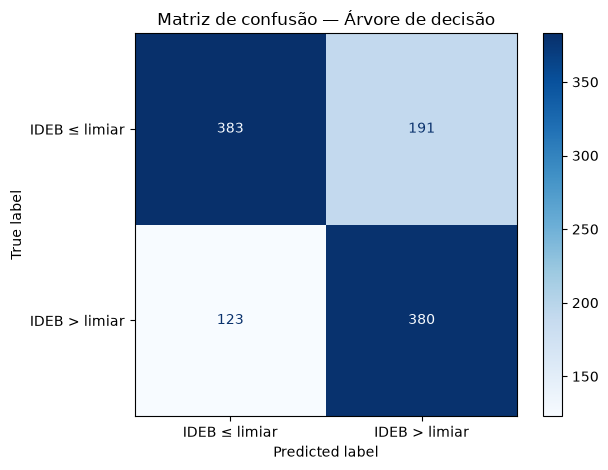

In [21]:
f1_validacao = {
    "KNN": busca_knn.best_score_,
    "Árvore de decisão": busca_arvore.best_score_,
    "Random Forest": busca_random_forest.best_score_,
    "Gradient Boosting": busca_gradient_boosting.best_score_
}

melhor_nome = max(f1_validacao, key=f1_validacao.get)
melhor_modelo = modelos[melhor_nome]

print("Modelo escolhido pela validação cruzada:", melhor_nome)
print(f"F1 médio na validação cruzada: {f1_validacao[melhor_nome]:.3f}")

ConfusionMatrixDisplay.from_estimator(
    melhor_modelo,
    X_teste,
    y_teste,
    display_labels=[
        "IDEB ≤ limiar",
        "IDEB > limiar"
    ],
    cmap="Blues"
)

plt.title(f"Matriz de confusão — {melhor_nome}")
plt.tight_layout()
plt.show()

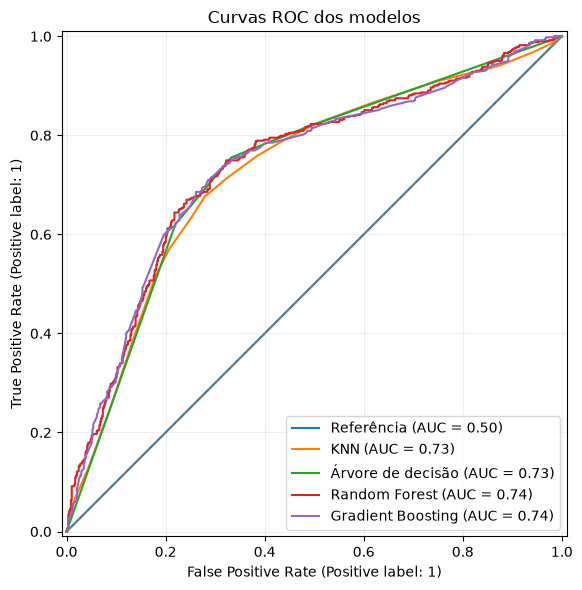

In [22]:
plt.figure(figsize=(8, 6))

for nome, modelo in modelos.items():
    RocCurveDisplay.from_estimator(
        modelo,
        X_teste,
        y_teste,
        name=nome,
        ax=plt.gca()
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Classificador aleatório"
)

plt.title("Curvas ROC dos modelos")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Importância das variáveis

A seguir, será observada a importância atribuída à população e à renda
pelos modelos baseados em árvores. Essa medida indica como cada variável
foi utilizada pelos modelos para realizar suas divisões.

Os valores de importância descrevem o comportamento dos modelos
ajustados. Eles não representam efeitos causais e devem ser interpretados
considerando que foram usadas apenas duas variáveis preditoras.

In [23]:
modelos_com_importancia = {
    "Árvore de decisão": busca_arvore.best_estimator_,
    "Random Forest": busca_random_forest.best_estimator_,
    "Gradient Boosting": busca_gradient_boosting.best_estimator_
}

importancias = pd.DataFrame({
    nome: modelo.feature_importances_
    for nome, modelo in modelos_com_importancia.items()
}, index=variaveis_preditora)

display(importancias.round(3))

,Árvore de decisão,Random Forest,Gradient Boosting
log_populacao_2022,0.0,0.214,0.092
renda_domiciliar_per_capita_2022,1.0,0.786,0.908


In [24]:
arquivo_resultados_classicos = (
    DATA_PROCESSED / "resultados_modelos_classicos.csv"
)

tabela_resultados.to_csv(
    arquivo_resultados_classicos,
    index=False,
    encoding="utf-8-sig"
)

print("Resultados salvos em:", arquivo_resultados_classicos.resolve())

Resultados salvos em: C:\Users\manel\Documents\Ciencia de Dados\brasil_em_dados\data\processed\resultados_modelos_classicos.csv


## 9. Síntese dos resultados e limitações

A árvore de decisão apresentou o maior F1 médio na validação cruzada
(0,697) e também o maior F1 no conjunto de teste (0,708). Seu recall foi
0,755, indicando que identificou cerca de 75,5% dos municípios com IDEB
acima do limiar. A Random Forest apresentou a maior AUC no teste (0,739),
enquanto o Gradient Boosting obteve a maior acurácia (0,711).

Os modelos superaram o modelo de referência em F1, mas apresentaram
capacidade de classificação moderada. Como foram usados somente o
logaritmo da população e o rendimento domiciliar per capita, os
resultados avaliam a informação contida nessas duas variáveis, e não
permitem prever ou explicar completamente o desempenho educacional dos
municípios.

Nas árvores e nos ensembles, o rendimento domiciliar per capita recebeu
maior importância do que o logaritmo da população. Essa importância
descreve como os modelos utilizaram as variáveis; não demonstra que a
renda cause mudanças no IDEB.

Transformar o IDEB em duas classes simplifica a análise, mas perde
informação sobre as diferenças numéricas entre os municípios. A mediana
do conjunto de treino foi adotada como limiar didático e não representa
uma classificação oficial de qualidade educacional.

Por fim, municípios de uma mesma região podem compartilhar
características. Como a divisão entre treino e teste foi aleatória, esta
avaliação não mede especificamente o desempenho do modelo em regiões
inteiramente novas. Os resultados também não devem ser generalizados
automaticamente para outros anos ou indicadores.